Initializing Mobile Robot Path Planning via PSO...
Initial Global Best Cost: 25.5874
Iteration 015/150 | Current Best Cost: 15.0574
Iteration 030/150 | Current Best Cost: 14.9932
Iteration 045/150 | Current Best Cost: 14.9210
Iteration 060/150 | Current Best Cost: 14.9159
Iteration 075/150 | Current Best Cost: 14.9093
Iteration 090/150 | Current Best Cost: 14.9071
Iteration 105/150 | Current Best Cost: 14.9060
Iteration 120/150 | Current Best Cost: 14.9058
Iteration 135/150 | Current Best Cost: 14.9053
Iteration 150/150 | Current Best Cost: 14.9053

Convergence Achieved. Optimal Target Cost Value: 14.9053


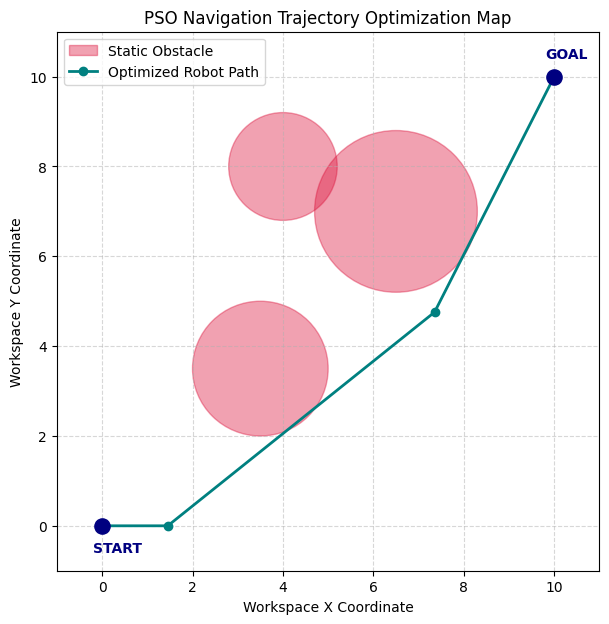

In [3]:
import numpy as np
import matplotlib.pyplot as plt

START = np.array([0.0, 0.0])
GOAL = np.array([10.0, 10.0])

OBSTACLES = [
    np.array([3.5, 3.5, 1.5]),
    np.array([6.5, 7.0, 1.8]),
    np.array([4.0, 8.0, 1.2])
]

NUM_WAYPOINTS = 5
DIMENSION = NUM_WAYPOINTS * 2

def reconstruct_path(waypoints):
    points = [START]
    coords = waypoints.reshape((NUM_WAYPOINTS, 2))
    points.extend(coords)
    points.append(GOAL)
    return np.array(points)

def evaluate_fitness(waypoints):
    path = reconstruct_path(waypoints)
    diffs = np.diff(path, axis=0)
    distance = np.sum(np.sqrt(np.sum(diffs**2, axis=1)))
    penalty = 0.0
    for i in range(len(path) - 1):
        p1, p2 = path[i], path[i+1]
        for t in np.linspace(0, 1, 10):
            sampled_point = p1 + t * (p2 - p1)
            for obs in OBSTACLES:
                obs_center = obs[:2]
                obs_radius = obs[2]
                dist_to_center = np.linalg.norm(sampled_point - obs_center)
                if dist_to_center <= obs_radius:
                    penalty += 1000.0 * (obs_radius - dist_to_center + 0.1)
    return distance + penalty

def execute_pso(num_particles=40, max_iter=150):
    bounds_min, bounds_max = 0.0, 10.0
    w = 0.729
    c1 = 1.494
    c2 = 1.494

    X = np.random.uniform(bounds_min, bounds_max, (num_particles, DIMENSION))
    V = np.random.uniform(-1.0, 1.0, (num_particles, DIMENSION))

    pbest_X = np.copy(X)
    pbest_fit = np.array([evaluate_fitness(p) for p in X])

    gbest_idx = np.argmin(pbest_fit)
    gbest_X = np.copy(pbest_X[gbest_idx])
    gbest_fit = pbest_fit[gbest_idx]

    print(f"Initial Global Best Cost: {gbest_fit:.4f}")

    for iteration in range(max_iter):
        for i in range(num_particles):
            r1, r2 = np.random.rand(DIMENSION), np.random.rand(DIMENSION)
            V[i] = (w * V[i]
                    + c1 * r1 * (pbest_X[i] - X[i])
                    + c2 * r2 * (gbest_X - X[i]))
            X[i] += V[i]
            X[i] = np.clip(X[i], bounds_min, bounds_max)
            current_fit = evaluate_fitness(X[i])
            if current_fit < pbest_fit[i]:
                pbest_fit[i] = current_fit
                pbest_X[i] = np.copy(X[i])
                if current_fit < gbest_fit:
                    gbest_fit = current_fit
                    gbest_X = np.copy(X[i])
        if (iteration + 1) % 15 == 0 or (iteration + 1) == max_iter:
            print(f"Iteration {iteration + 1:03d}/{max_iter:03d} | Current Best Cost: {gbest_fit:.4f}")
    return gbest_X, gbest_fit

if __name__ == "__main__":
    print("Initializing Mobile Robot Path Planning via PSO...")
    optimal_waypoints, optimal_cost = execute_pso(num_particles=50, max_iter=150)
    print(f"\nConvergence Achieved. Optimal Target Cost Value: {optimal_cost:.4f}")

    final_trajectory = reconstruct_path(optimal_waypoints)
    fig, ax = plt.subplots(figsize=(7, 7))

    for index, obs in enumerate(OBSTACLES):
        label = 'Static Obstacle' if index == 0 else ""
        circle = plt.Circle((obs[0], obs[1]), obs[2], color='crimson', alpha=0.4, label=label)
        ax.add_patch(circle)

    ax.plot(final_trajectory[:, 0], final_trajectory[:, 1],
            marker='o', color='teal', linewidth=2, label='Optimized Robot Path')

    ax.scatter([START[0], GOAL[0]], [START[1], GOAL[1]], color='navy', zorder=5, s=120)
    ax.text(START[0]-0.2, START[1]-0.6, "START", fontweight='bold', color='navy')
    ax.text(GOAL[0]-0.2, GOAL[1]+0.4, "GOAL", fontweight='bold', color='navy')

    ax.set_xlim(-1, 11)
    ax.set_ylim(-1, 11)
    ax.set_xlabel("Workspace X Coordinate")
    ax.set_ylabel("Workspace Y Coordinate")
    ax.set_title("PSO Navigation Trajectory Optimization Map")
    ax.legend(loc='upper left')
    ax.grid(True, linestyle='--', alpha=0.5)
    plt.show()